
# How Long Will the Battery Last?

## 1. Project Overview

**Course:** AI255TBD – Edge AI, Module 1  
**Team:** Team 13  
**Project Type:** Supervised Machine Learning – Regression

### 1.1 Project Objective

The objective of this project is to develop a neural network that predicts the remaining battery life of a smart doorbell in days using five sensor input features.

The model will be trained using the Team 13 dataset. After training and evaluation, the selected model will be saved and integrated into an API hosted through GitHub Codespaces.

### 1.2 Problem Statement

Smart doorbells rely on batteries to operate continuously. Their remaining battery life can be influenced by several factors, including battery voltage, operating temperature, daily usage, Wi-Fi signal strength and device age.

The objective is to analyse these sensor readings and develop a machine learning model capable of estimating the number of days remaining before the battery needs replacement.

### 1.3 Input Features

The model uses the following five input features:

| Feature | Description | Unit |
|---|---|---|
| `battery_v` | Battery voltage | Volts (V) |
| `temp_c` | Operating temperature | Degrees Celsius (°C) |
| `rings_per_day` | Number of rings per day | Rings/day |
| `wifi_rssi_dbm` | Received Wi-Fi signal strength | dBm |
| `age_months` | Age of the device | Months |

### 1.4 Target Variable

**Target:** `days_left`

The target represents the estimated remaining battery life of the smart doorbell, measured in days.

### 1.5 Machine Learning Problem

This project is a **Supervised Regression Problem**.

- **Supervised learning:** The training dataset contains input features along with their corresponding target values.
- **Regression:** The model predicts a continuous numerical value representing the remaining battery life in days.

The neural network learns relationships between the five sensor features and the target variable `days_left`.

### 1.6 Dataset

The project uses the Team 13 training dataset:

`data/team_13_train.csv`

All dataset analysis, preprocessing, model training and evaluation will be based on this dataset.



# 2. Dataset Understanding and Inspection

## 2.1 Loading the Dataset

The first step in dataset analysis is loading the Team 13 training dataset into a Pandas DataFrame.

The dataset is stored in CSV (Comma-Separated Values) format. Pandas provides the `read_csv()` function to read the CSV file and represent its contents in a structured tabular format.

**Dataset path:** `data/team_13_train.csv`

**Objective:**
- Load the Team 13 dataset.
- Store the dataset in a Pandas DataFrame.
- Verify that the dataset has been loaded successfully.

The loaded DataFrame will be used for subsequent dataset inspection, statistical analysis, exploratory data analysis and preprocessing.


In [1]:

import pandas as pd

# Load the Team 13 training dataset
df = pd.read_csv("data/team_13_train.csv")

# Display the first five records
df.head()


,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left
0,3.767,18.2,17,-85,35,19.1
1,4.184,24.3,4,-63,15,221.7
2,3.585,18.7,16,-50,35,14.8
3,3.480,10.0,11,-56,3,10.9
4,3.366,28.7,10,-47,0,2.6



### 2.1.1 Dataset Loading — Observations and Results

The Team 13 training dataset was successfully loaded into a Pandas DataFrame using the `read_csv()` function.

The `df.head()` function was used to display the first five records.

**Observations:**

1. The dataset contains the five expected input features: `battery_v`, `temp_c`, `rings_per_day`, `wifi_rssi_dbm` and `age_months`.
2. The target variable `days_left` is also present.
3. The displayed records contain numerical sensor readings and their corresponding target values.
4. Wi-Fi RSSI readings are represented using negative values.
5. The displayed records show variation in sensor readings and predicted target values.

**Conclusion:**

The dataset was successfully loaded, and the expected input features and target variable are present. The DataFrame is ready for further structural and statistical inspection.

The complete dataset dimensions, data types, missing values and other data-quality characteristics will be examined in the subsequent steps.



## 2.2 Dataset Dimensions, Columns and Data Types

After loading the Team 13 dataset, the next step is to inspect its overall structure.

This analysis focuses on understanding the dimensions of the dataset, identifying its columns, examining the data types and checking the structural information of the DataFrame.

**Objectives:**

1. Determine the total number of observations (rows).
2. Determine the total number of variables (columns).
3. Identify all column names.
4. Examine the data type of each column.
5. Inspect the overall DataFrame structure and memory usage.

These checks help verify that the dataset is structurally suitable for further statistical analysis and machine learning preprocessing.


In [2]:

# 1. Display dataset dimensions
print("Dataset Dimensions:")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

# 2. Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Display dataset structure and data types
print("\nDataset Information:")
df.info()


Dataset Dimensions:
Rows: 2000
Columns: 6

Column Names:
['battery_v', 'temp_c', 'rings_per_day', 'wifi_rssi_dbm', 'age_months', 'days_left']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_v      2000 non-null   float64
 1   temp_c         2000 non-null   float64
 2   rings_per_day  2000 non-null   int64  
 3   wifi_rssi_dbm  2000 non-null   int64  
 4   age_months     2000 non-null   int64  
 5   days_left      2000 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 93.9 KB



### 2.2.1 Dataset Structure — Observations and Results

The Team 13 dataset was inspected using the Pandas `shape`, `columns` and `info()` properties and methods.

**1. Dataset Dimensions**

- Total observations: 2,000 rows.
- Total variables: 6 columns.
- The dataset contains five input features and one target variable.

**2. Column Verification**

The following six columns were identified:

- `battery_v`
- `temp_c`
- `rings_per_day`
- `wifi_rssi_dbm`
- `age_months`
- `days_left`

All expected input features and the target variable are present.

**3. Data Types**

The dataset contains:

- Three `float64` columns: `battery_v`, `temp_c` and `days_left`.
- Three `int64` columns: `rings_per_day`, `wifi_rssi_dbm` and `age_months`.

All six columns are stored as numerical data types.

**4. Non-Null Entries**

Each column contains 2,000 non-null entries. No missing values are indicated by the initial DataFrame information output.

This observation will be verified separately during the missing-value analysis.

**5. Memory Usage**

The DataFrame reports a memory usage of approximately 93.9 KB.

**Conclusion:**

The dataset contains 2,000 observations and six numerical columns. All expected input features and the target variable are present, and their data types are suitable for numerical analysis.

The initial structural inspection indicates that the dataset is ready for further data-quality checks and statistical analysis.



## 2.3 Missing Value Analysis

Missing value analysis is performed to identify whether any observations contain incomplete information.

Missing values can affect statistical calculations, data preprocessing and machine learning model training.

**Objectives:**

1. Identify missing values in each column.
2. Calculate the number of missing entries per column.
3. Determine the total number of missing values in the dataset.
4. Identify whether any columns contain incomplete observations.

This analysis helps determine whether missing-value handling is required before further data processing.


In [3]:

# Check missing values in each column
print("Missing Values Per Column:")
print(df.isnull().sum())

# Calculate total missing values
total_missing = df.isnull().sum().sum()

print("\nTotal Missing Values in Dataset:")
print(total_missing)

# Calculate missing value percentage per column
print("\nMissing Value Percentage Per Column:")
print((df.isnull().mean() * 100).round(2))


Missing Values Per Column:
battery_v        0
temp_c           0
rings_per_day    0
wifi_rssi_dbm    0
age_months       0
days_left        0
dtype: int64

Total Missing Values in Dataset:
0

Missing Value Percentage Per Column:
battery_v        0.0
temp_c           0.0
rings_per_day    0.0
wifi_rssi_dbm    0.0
age_months       0.0
days_left        0.0
dtype: float64



### 2.3.1 Missing Value Analysis — Observations and Results

Missing-value analysis was performed using Pandas `isnull()` to identify incomplete entries in the dataset.

**1. Missing Values Per Column**

The analysis identified zero missing values in all six columns:

- `battery_v`: 0
- `temp_c`: 0
- `rings_per_day`: 0
- `wifi_rssi_dbm`: 0
- `age_months`: 0
- `days_left`: 0

**2. Total Missing Values**

The total number of missing values across the entire dataset is 0.

**3. Missing Value Percentage**

All six columns have a missing-value percentage of 0.0%.

**Conclusion:**

The Team 13 dataset contains no missing or null entries according to the Pandas missing-value check. Therefore, no missing-value imputation or row removal is required at this stage.

However, the absence of missing values does not guarantee that all sensor readings are valid. Further data-quality checks will be performed to investigate duplicate records and potentially suspicious sensor values.



## 2.4 Duplicate Record Analysis

Duplicate analysis is performed to identify whether the dataset contains repeated observations.

An exact duplicate occurs when all column values in a row match another row.

**Objectives:**

1. Identify exact duplicate records across all columns.
2. Calculate the total number of duplicate rows.
3. Determine the percentage of duplicate records in the dataset.
4. Assess whether duplicate records require further investigation or removal.

Duplicate records can influence statistical analysis and model evaluation, particularly when repeated observations are distributed across training and validation datasets.

No records will be removed automatically during this inspection.


In [4]:

# Identify exact duplicate records
duplicate_count = df.duplicated().sum()

# Calculate duplicate percentage
duplicate_percentage = (duplicate_count / len(df)) * 100

# Display results
print("Duplicate Record Analysis:")
print(f"Total records: {len(df)}")
print(f"Duplicate records: {duplicate_count}")
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

# Display duplicate rows, if any
print("\nDuplicate Records:")
display(df[df.duplicated()])


Duplicate Record Analysis:
Total records: 2000
Duplicate records: 0
Duplicate percentage: 0.00%

Duplicate Records:


,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left



### 2.4.1 Observations and Conclusion

- Total records: 2,000.
- Exact duplicate records: 0.
- Duplicate percentage: 0.00%.

**Conclusion:** No exact duplicate rows were identified across the six columns. Therefore, no records require removal due to exact duplication.



## 2.5 Descriptive Statistical Analysis

Descriptive statistics are calculated to understand the numerical characteristics and variability of the dataset.

The analysis includes count, mean, standard deviation, minimum, maximum and quartiles for each numerical column.

**Objective:** Understand the central tendency, spread and range of sensor readings and the target variable.


In [5]:

# Calculate descriptive statistics for all numerical columns
print("Descriptive Statistical Summary:")
display(df.describe())


Descriptive Statistical Summary:


,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,3.756825,27.165150,7.938500,-66.298000,18.205000,75.554550
std,0.371475,11.936212,5.631303,12.547108,10.661745,67.287199
min,0.000000,-127.000000,0.000000,-88.000000,0.000000,0.200000
25%,3.560000,22.975000,4.000000,-76.000000,9.000000,19.975000
50%,3.772000,27.900000,7.000000,-66.000000,18.000000,59.450000
75%,3.985250,32.400000,11.000000,-56.000000,27.000000,114.400000
max,4.200000,46.000000,44.000000,0.000000,36.000000,367.200000



### 2.5.1 Observations and Conclusion

- Dataset contains 2,000 observations across six numerical columns.
- Mean battery voltage: 3.757 V.
- Mean temperature: 27.17°C.
- Mean daily usage: 7.94 rings.
- Mean device age: 18.21 months.
- Mean remaining battery life: 75.55 days.
- `days_left` has a standard deviation of 67.29 days.
- The minimum battery voltage (0 V) and temperature (-127°C) require further investigation.

**Conclusion:** The descriptive statistics reveal variation across sensor readings and the target variable. Potentially suspicious minimum values were identified and will be investigated during subsequent data-quality analysis.



## 2.6 Unique Values and Value Range Analysis

This analysis examines the distinct values and numerical ranges of each dataset column.

**Objectives:**
- Count unique values in each column.
- Identify minimum and maximum values.
- Examine distinct readings in integer-based features.
- Identify unusual values for further investigation.


In [6]:

# 1. Unique value count for each column
print("Unique Value Counts:")
print(df.nunique())

# 2. Minimum and maximum values
print("\nValue Ranges:")
print(df.agg(["min", "max"]).T)

# 3. Display distinct values in integer-based columns
integer_columns = df.select_dtypes(include="int64").columns

print("\nUnique Values in Integer Columns:")
for col in integer_columns:
    print(f"\n{col}:")
    print(sorted(df[col].unique()))

# 4. Display sample unique values in decimal-based columns
float_columns = df.select_dtypes(include="float64").columns

print("\nSample Unique Values in Float Columns:")
for col in float_columns:
    values = sorted(df[col].unique())
    print(f"\n{col}: {values[:10]}")
    print(f"Total unique values: {len(values)}")


Unique Value Counts:
battery_v         777
temp_c            316
rings_per_day      37
wifi_rssi_dbm      45
age_months         37
days_left        1190
dtype: int64

Value Ranges:
                 min    max
battery_v        0.0    4.2
temp_c        -127.0   46.0
rings_per_day    0.0   44.0
wifi_rssi_dbm  -88.0    0.0
age_months       0.0   36.0
days_left        0.2  367.2

Unique Values in Integer Columns:

rings_per_day:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(36), np.int64(44)]

wifi_rssi_dbm:
[np.int64(-88), np.int64(-87), np.int64(-86), n


### 2.6.1 Observations and Conclusion

- `battery_v`: 777 unique values, ranging from 0 to 4.2 V.
- `temp_c`: 316 unique values, ranging from -127°C to 46°C.
- `rings_per_day`: 37 unique values, ranging from 0 to 44.
- `wifi_rssi_dbm`: 45 unique values, ranging from -88 to 0 dBm.
- `age_months`: 37 unique values, ranging from 0 to 36 months.
- `days_left`: 1,190 unique values, ranging from 0.2 to 367.2 days.

**Conclusion:** The dataset contains varying numbers of distinct values across its features. The minimum battery voltage of 0 V and temperature of -127°C are potential sensor anomalies requiring further investigation.



## 2.7 Quartiles, Skewness and Distribution Analysis

This analysis examines the spread and shape of numerical feature distributions.

**Objectives:**
- Examine Q1, median and Q3.
- Calculate skewness for each numerical column.
- Visualise feature distributions using histograms.
- Identify potentially skewed distributions and unusual patterns.


Quartile Analysis:


,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left
0.25,3.56000,22.975,4.0,-76.0,9.0,19.975
0.50,3.77200,27.900,7.0,-66.0,18.0,59.450
0.75,3.98525,32.400,11.0,-56.0,27.0,114.400



Skewness Analysis:
battery_v       -5.620
temp_c          -8.580
rings_per_day    1.411
wifi_rssi_dbm    0.340
age_months       0.001
days_left        1.174
dtype: float64


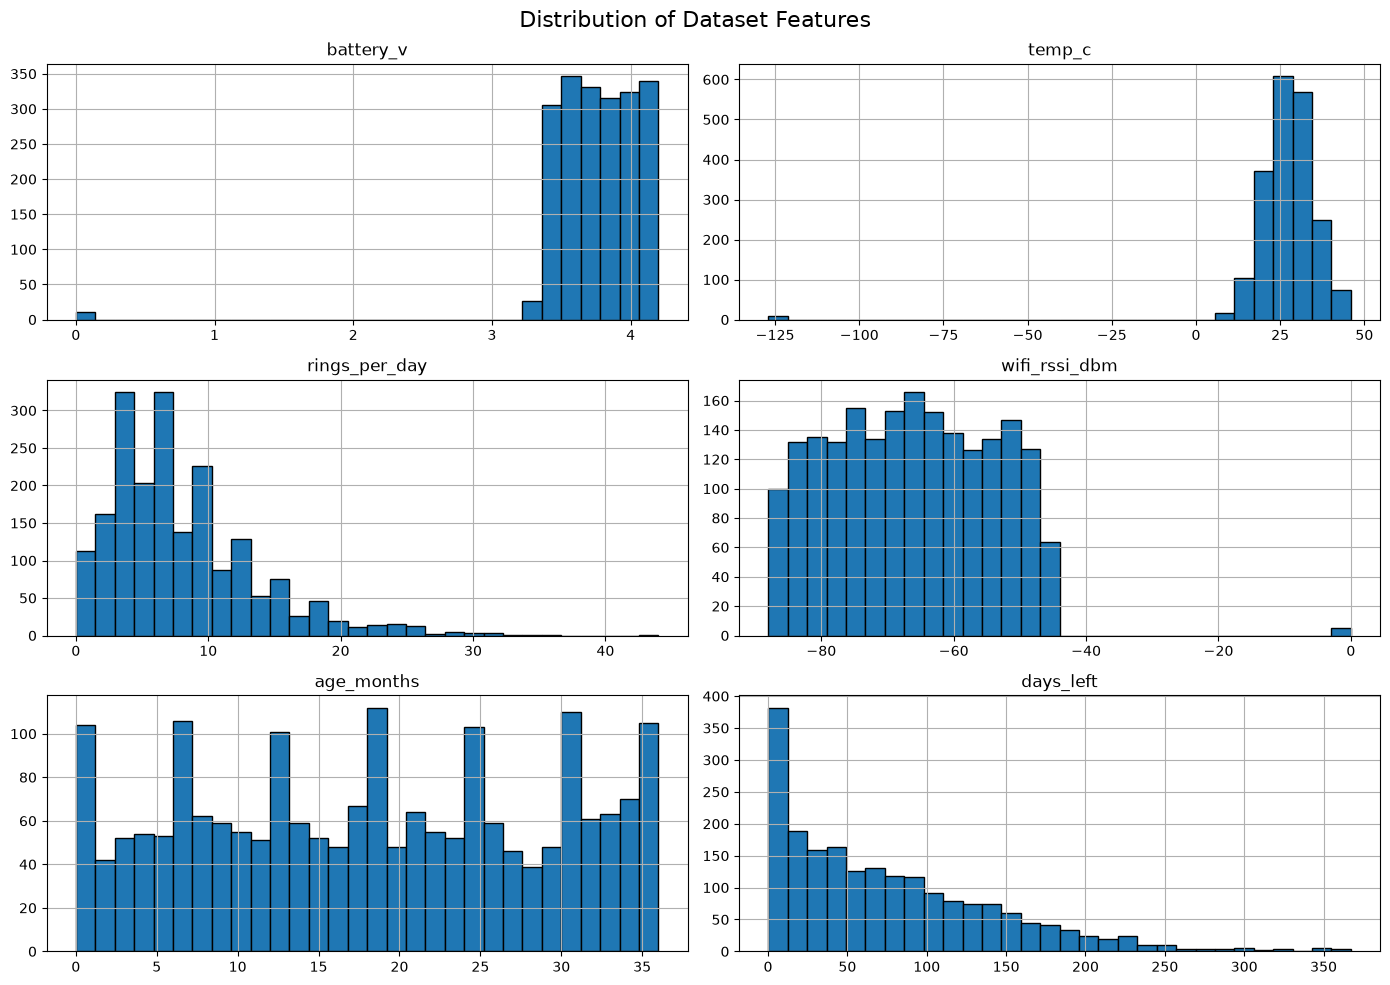

In [7]:

import matplotlib.pyplot as plt

# 1. Calculate quartiles
print("Quartile Analysis:")
display(df.quantile([0.25, 0.50, 0.75]))

# 2. Calculate skewness
print("\nSkewness Analysis:")
print(df.skew().round(3))

# 3. Plot distributions of all numerical columns
df.hist(figsize=(14, 10), bins=30, edgecolor="black")
plt.suptitle("Distribution of Dataset Features", fontsize=16)
plt.tight_layout()
plt.show()



### 2.7.1 Observations and Conclusion

- Battery voltage and temperature show strong negative skewness (-5.620 and -8.580).
- Daily usage and remaining battery life show positive skewness (1.411 and 1.174).
- Wi-Fi RSSI has slight positive skewness (0.340).
- Device age is approximately symmetric (0.001).
- Histograms reveal isolated values at 0 V, -127°C and 0 dBm.
- Remaining battery life has a long right tail.

**Conclusion:** The feature distributions exhibit different patterns of variability and skewness. Potential sensor anomalies were identified in battery voltage, temperature and Wi-Fi RSSI for further investigation.



## 2.8 Initial Data-Quality Assessment

This section consolidates the findings from the dataset inspection and statistical analysis to identify potential data-quality concerns.

**Objectives:**
- Summarise missing-value and duplicate checks.
- Identify unusual sensor readings and value ranges.
- Review distribution and skewness patterns.
- Record potential issues requiring further investigation during preprocessing.


In [8]:

# Consolidated data-quality assessment

quality_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Unique Values": df.nunique(),
    "Minimum": df.min(),
    "Maximum": df.max(),
    "Skewness": df.skew().round(3)
})

print("Initial Data Quality Summary:")
display(quality_summary)

print("\nTotal Duplicate Records:", df.duplicated().sum())
print("Total Missing Values:", df.isnull().sum().sum())


Initial Data Quality Summary:


,Missing Values,Unique Values,Minimum,Maximum,Skewness
battery_v,0,777,0.0,4.2,-5.620
temp_c,0,316,-127.0,46.0,-8.580
rings_per_day,0,37,0.0,44.0,1.411
wifi_rssi_dbm,0,45,-88.0,0.0,0.340
age_months,0,37,0.0,36.0,0.001
days_left,0,1190,0.2,367.2,1.174



Total Duplicate Records: 0
Total Missing Values: 0



### 2.8.1 Observations and Conclusion

- Dataset contains 2,000 records and six numerical columns.
- No missing values or exact duplicate records were identified.
- Potential anomalies include battery voltage of 0 V, temperature of -127°C and Wi-Fi RSSI of 0 dBm.
- Battery voltage and temperature exhibit strong negative skewness.
- Daily usage and remaining battery life exhibit positive skewness.

**Conclusion:** The dataset is structurally complete but contains potentially suspicious sensor readings and skewed distributions. These observations will guide the subsequent data-cleaning and preprocessing stages.
